In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
import seaborn as sns
import warnings
import json
import pymongo
import re
warnings.filterwarnings("ignore")
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号
pd.set_option('display.max_rows', 100,'display.max_columns', 1000,"display.max_colwidth",1000,'display.width',1000)


In [2]:
warnings.filterwarnings("ignore")
plt.rcParams['font.sans-serif'] = ['SimHei']  # 用来正常显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 用来正常显示负号
pd.set_option('display.max_rows', 100,'display.max_columns', 1000,"display.max_colwidth",1000,'display.width',1000)
data = pd.read_excel(r"C:\Users\wang\Desktop\毕设论文\房价预测代码\data\Augmented_链家杭州二手房数据_10000.xlsx", na_values=np.nan)

# 看一下数据维度
print(data.shape) # (2984, 31)

# 看一下数据的前五行
data.head()

# 输出数据的info
data.info()

(10000, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 31 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   总价      10000 non-null  float64
 1   单位价格    10000 non-null  object 
 2   楼房信息    10000 non-null  object 
 3   小区      10000 non-null  object 
 4   所属区县    10000 non-null  object 
 5   房屋户型    10000 non-null  object 
 6   所在楼层    10000 non-null  object 
 7   建筑面积    10000 non-null  object 
 8   户型结构    9953 non-null   object 
 9   套内面积    10000 non-null  object 
 10  建筑类型    9941 non-null   object 
 11  房屋朝向    10000 non-null  object 
 12  建筑结构    10000 non-null  object 
 13  装修情况    10000 non-null  object 
 14  梯户比例    9954 non-null   object 
 15  供暖方式    10000 non-null  object 
 16  配备电梯    9936 non-null   object 
 17  挂牌时间    10000 non-null  object 
 18  交易权属    10000 non-null  object 
 19  上次交易    10000 non-null  object 
 20  房屋用途    10000 non-null  object 
 21  房屋年限    10000 non-null  

In [3]:
data = data[data.columns[:-4]]

# 再看一下数据
data.head()


,总价,单位价格,楼房信息,小区,所属区县,房屋户型,所在楼层,建筑面积,户型结构,套内面积,建筑类型,房屋朝向,建筑结构,装修情况,梯户比例,供暖方式,配备电梯,挂牌时间,交易权属,上次交易,房屋用途,房屋年限,产权所属,抵押信息,房本备件,户型分间,小区简介
0,179.0,14512元/平米,2014年建/板楼,富海澜湾半岛,拱墅区,3室2厅1厨2卫,高楼层 (共34层),123.35㎡,平层,暂无数据,板楼,南 北,钢混结构,精装,两梯两户,集中供暖,有,2022-04-17,商品房,2019-06-03,普通住宅,满两年,共有,有抵押90万元盛京银行业主自还,已上传房本照片,"{'客厅面积': '38.13平米', '客厅朝向': '无', '客厅窗型': '未知窗户类型', '卧室A面积': '11.34平米', '卧室A朝向': '无', '卧室A窗型': '未知窗户类型', '卧室B面积': '15.78平米', '卧室B朝向': '南', '卧室B窗型': '普通窗', '卧室C面积': '10.89平米', '卧室C朝向': '无', '卧室C窗型': '未知窗户类型', '厨房面积': '5.3平米', '厨房朝向': '无', '厨房窗型': '未知窗户类型', '卫生间A面积': '4.1平米', '卫生间A朝向': '无', '卫生间A窗型': '无窗', '卫生间B面积': '3.43平米', '卫生间B朝向': '无', '卫生间B窗型': '无窗'}","{'小区建造年份': '2013年', '楼栋总数': '27栋', '小区均价': 17465}"
1,105.0,9740元/平米,2011年建/板楼,东星花庭,钱塘新区,3室2厅1厨1卫,中楼层 (共24层),107.81㎡,平层,暂无数据,板楼,南 北,钢混结构,精装,两梯四户,集中供暖,有,2022-04-22,商品房,2015-10-14,普通住宅,满五年,非共有,无抵押,已上传房本照片,"{'客厅面积': '31.31平米', '客厅朝向': '无', '客厅窗型': '未知窗户类型', '卧室A面积': '8.91平米', '卧室A朝向': '北', '卧室A窗型': '普通窗', '卧室B面积': '9.76平米', '卧室B朝向': '北', '卧室B窗型': '普通窗', '卧室C面积': '12.57平米', '卧室C朝向': '南', '卧室C窗型': '普通窗', '厨房面积': '7.97平米', '厨房朝向': '北', '厨房窗型': '普通窗', '卫生间面积': '3.91平米', '卫生间朝向': '北', '卫生间窗型': '普通窗', '洗手间面积': '1.95平米', '洗手间朝向': '无', '洗手间窗型': '无窗'}","{'小区建造年份': '1999年', '楼栋总数': '5栋', '小区均价': 9590}"
2,67.8,8693元/平米,2000年建/板塔结合,北舍宅,萧山区,2室1厅1厨1卫,高楼层 (共7层),78㎡,平层,暂无数据,板塔结合,东 西,混合结构,简装,一梯两户,集中供暖,无,2022-04-19,商品房,2018-08-02,普通住宅,满两年,非共有,无抵押,已上传房本照片,"{'客厅面积': '17.54平米', '客厅朝向': '无', '客厅窗型': '无窗', '卧室A面积': '14.85平米', '卧室A朝向': '南', '卧室A窗型': '普通窗', '卧室B面积': '13.43平米', '卧室B朝向': '南', '卧室B窗型': '普通窗', '厨房面积': '7.69平米', '厨房朝向': '北', '厨房窗型': '普通窗', '卫生间面积': '5.35平米', '卫生间朝向': '无', '卫生间窗型': '无窗', '阳台面积': '4.47平米', '阳台朝向': '西 北 东', '阳台窗型': '普通窗'}","{'小区建造年份': '1990年', '楼栋总数': '13栋', '小区均价': 14413}"
3,179.0,13426元/平米,2010年建/板楼,首创国际城,滨江区,3室2厅1厨2卫,低楼层 (共24层),133.33㎡,平层,暂无数据,板楼,南 北,钢混结构,精装,两梯三户,集中供暖,有,2021-12-11,商品房,2016-08-17,普通住宅,满五年,非共有,无抵押,已上传房本照片,"{'客厅面积': '27.16平米', '客厅朝向': '西 南', '客厅窗型': '落地窗', '卧室A面积': '11.8平米', '卧室A朝向': '南', '卧室A窗型': '落地窗', '卧室B面积': '15.48平米', '卧室B朝向': '无', '卧室B窗型': '未知窗户类型', '卧室C面积': '9.36平米', '卧室C朝向': '无', '卧室C窗型': '未知窗户类型', '厨房面积': '15.38平米', '厨房朝向': '北', '厨房窗型': '落地窗', '卫生间A面积': '4.87平米', '卫生间A朝向': '北', '卫生间A窗型': '普通窗', '卫生间B面积': '5.22平米', '卫生间B朝向': '北', '卫生间B窗型': '落地窗', '阳台面积': '7.92平米', '阳台朝向': '西 北 东', '阳台窗型': '落地窗', '过道A面积': '5.45平米', '过道A朝向': '无', '过道A窗型': '无窗', '过道B面积': '4.06平米', '过道B朝向': '无', '过道B窗型': '无窗'}","{'小区建造年份': '2009年', '楼栋总数': '27栋', '小区均价': 11637}"
4,90.0,7987元/平米,未知年建/板楼,雅居乐花园C地块,江干区,3室2厅1厨2卫,高楼层 (共32层),112.69㎡,平层,暂无数据,板楼,南 北,钢混结构,精装,一梯两户,集中供暖,有,2022-04-15,商品房,2016-05-06,普通住宅,满五年,共有,无抵押,已上传房本照片,"{'客厅面积': '42.56平米', '客厅朝向': '东 南', '客厅窗型': '落地窗', '卧室A面积': '16.82平米', '卧室A朝向': '南', '卧室A窗型': '普通窗', '卧室B面积': '15.71平米', '卧室B朝向': '南', '卧室B窗型': '普通窗', '卧室C面积': '7.5平米', '卧室C朝向': '北', '卧室C窗型': '普通窗', '厨房面积': '5.3平米', '厨房朝向': '西', '厨房窗型': '普通窗', '卫生间A面积': '4.2平米', '卫生间A朝向': '无', '卫生间A窗型': '无窗', '卫生间B面积': '4.04平米', '卫生间B朝向': '无', '卫生间B窗型': '无窗'}","{'小区建造年份': '2009年', '楼栋总数': '38栋', '小区均价': 9263}"


In [4]:
data['单位价格'] = data['单位价格'].str[:-4]
data['单位价格'] = data['单位价格'].astype(float)

data['楼房信息'] = data['楼房信息'].str[:4]
data['楼房信息'].value_counts()


楼房信息
未知年建    2248
2018     613
2017     604
2012     602
2019     599
2016     592
2015     539
2009     489
2014     487
2010     425
2008     403
2013     379
2011     372
2020     293
2006     230
2007     217
2005     191
2000     151
2004     114
2021     109
1999      77
1998      51
2003      49
2002      32
1997      31
1995      30
1996      21
2001      16
1990      15
1994       6
1992       6
1987       5
2090       2
2121       2
Name: count, dtype: int64

In [5]:
# 定义填补函数
def fillBuildYear(df):
    if df['楼房信息'] == "未知年建":
        xiaoqu = json.loads(df['小区简介'].replace("'", '"'))
        return xiaoqu['小区建造年份'][:4]
    else:
        return df['楼房信息']
# 进行填补
data['楼房信息'] = data.apply(lambda x:fillBuildYear(x), axis=1)

In [6]:
# 再看一下
data['楼房信息'].value_counts()

楼房信息
2012    723
2017    675
2018    649
2019    642
2009    634
2016    608
2015    602
2010    598
2014    596
2008    539
2013    415
2011    410
2000    384
2005    349
2006    338
2007    338
2020    306
2004    191
1999    132
2003    128
2021    118
1998     97
2002     78
1990     77
1995     71
1997     58
2001     56
1996     42
1992     18
1988     17
1980     14
1979     12
1987     12
1994     11
1989      9
1986      9
1978      7
1900      7
1983      6
1970      5
1973      4
1993      3
1955      2
1985      2
2121      2
2090      2
1958      1
1972      1
1960      1
1991      1
Name: count, dtype: int64

In [7]:
# 定义填补函数
def fillBuildYear(df):
    if df['楼房信息'] == "未知年建":
        xiaoqu = json.loads(df['小区简介'].replace("'", '"'))
        return xiaoqu['小区建造年份'][:4]
    else:
        return df['楼房信息']


In [8]:
print(data.columns)


Index(['总价', '单位价格', '楼房信息', '小区', '所属区县', '房屋户型', '所在楼层', '建筑面积', '户型结构', '套内面积', '建筑类型', '房屋朝向', '建筑结构', '装修情况', '梯户比例', '供暖方式', '配备电梯', '挂牌时间', '交易权属', '上次交易', '房屋用途', '房屋年限', '产权所属', '抵押信息', '房本备件', '户型分间', '小区简介'], dtype='object')


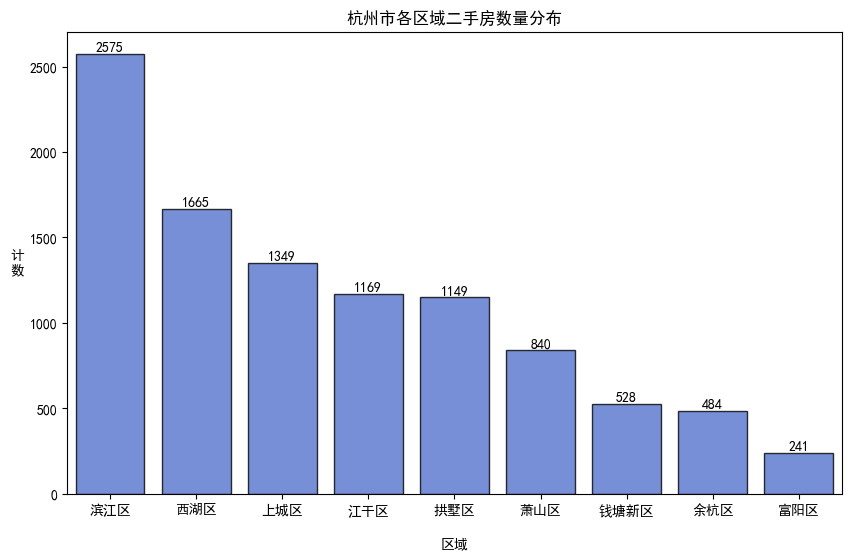

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

areaName = list(data['所属区县'].value_counts().index)
areaCountList = list(data['所属区县'].value_counts())

plt.figure(figsize=(10, 6))
plt.title("杭州市各区域二手房数量分布")
sns.barplot(x=areaName, y=areaCountList, alpha=0.8, color="royalblue", edgecolor="k")
plt.xlabel("\n区域")
plt.ylabel("计\n数", rotation='horizontal', verticalalignment='center', horizontalalignment='right')

for a, b in zip(range(len(areaName)), areaCountList):
    plt.text(a, b + 3, '%.f' % b, ha='center', va='bottom', fontsize=10)

plt.show()


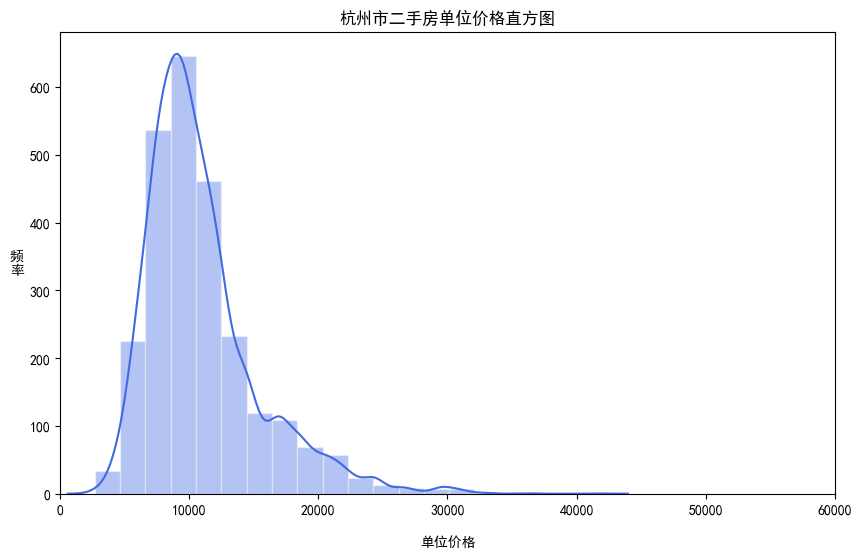

In [10]:
plt.figure(figsize=(10,6))
plt.title("杭州市二手房单位价格直方图")
sns.distplot(data['单位价格'], color="royalblue",bins=20, kde=True, hist_kws={"edgecolor":"w"})
plt.xlabel("\n单位价格")
plt.ylabel("频\n率", rotation = 'horizontal', verticalalignment = 'center', horizontalalignment = 'right')
yticks_list = ['0', '100', '200', '300', '400', '500', '600']
plt.yticks(np.arange(0.0, 0.00014, 0.00002), yticks_list)
plt.xlim(0,60000)
plt.show()


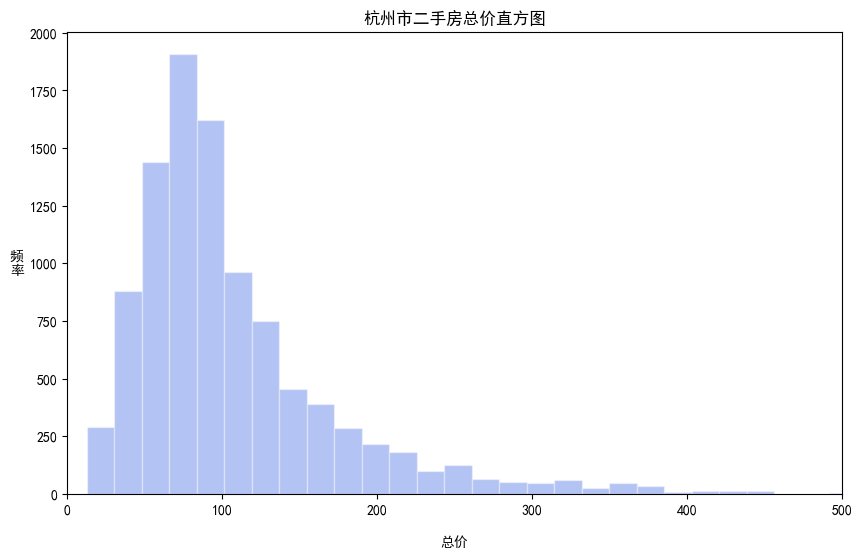

In [11]:
plt.figure(figsize=(10,6))
plt.title("杭州市二手房总价直方图")
sns.distplot(data['总价'], color="royalblue",bins=50, kde=False, hist_kws={"edgecolor":"w"})
plt.xlabel("\n总价")
plt.ylabel("频\n率", rotation = 'horizontal', verticalalignment = 'center', horizontalalignment = 'right')
# yticks_list = ['0', '100', '200', '300', '400', '500', '600']
# plt.yticks(np.arange(0.0, 0.00014, 0.00002), yticks_list)
plt.xlim(0,500)
plt.show()


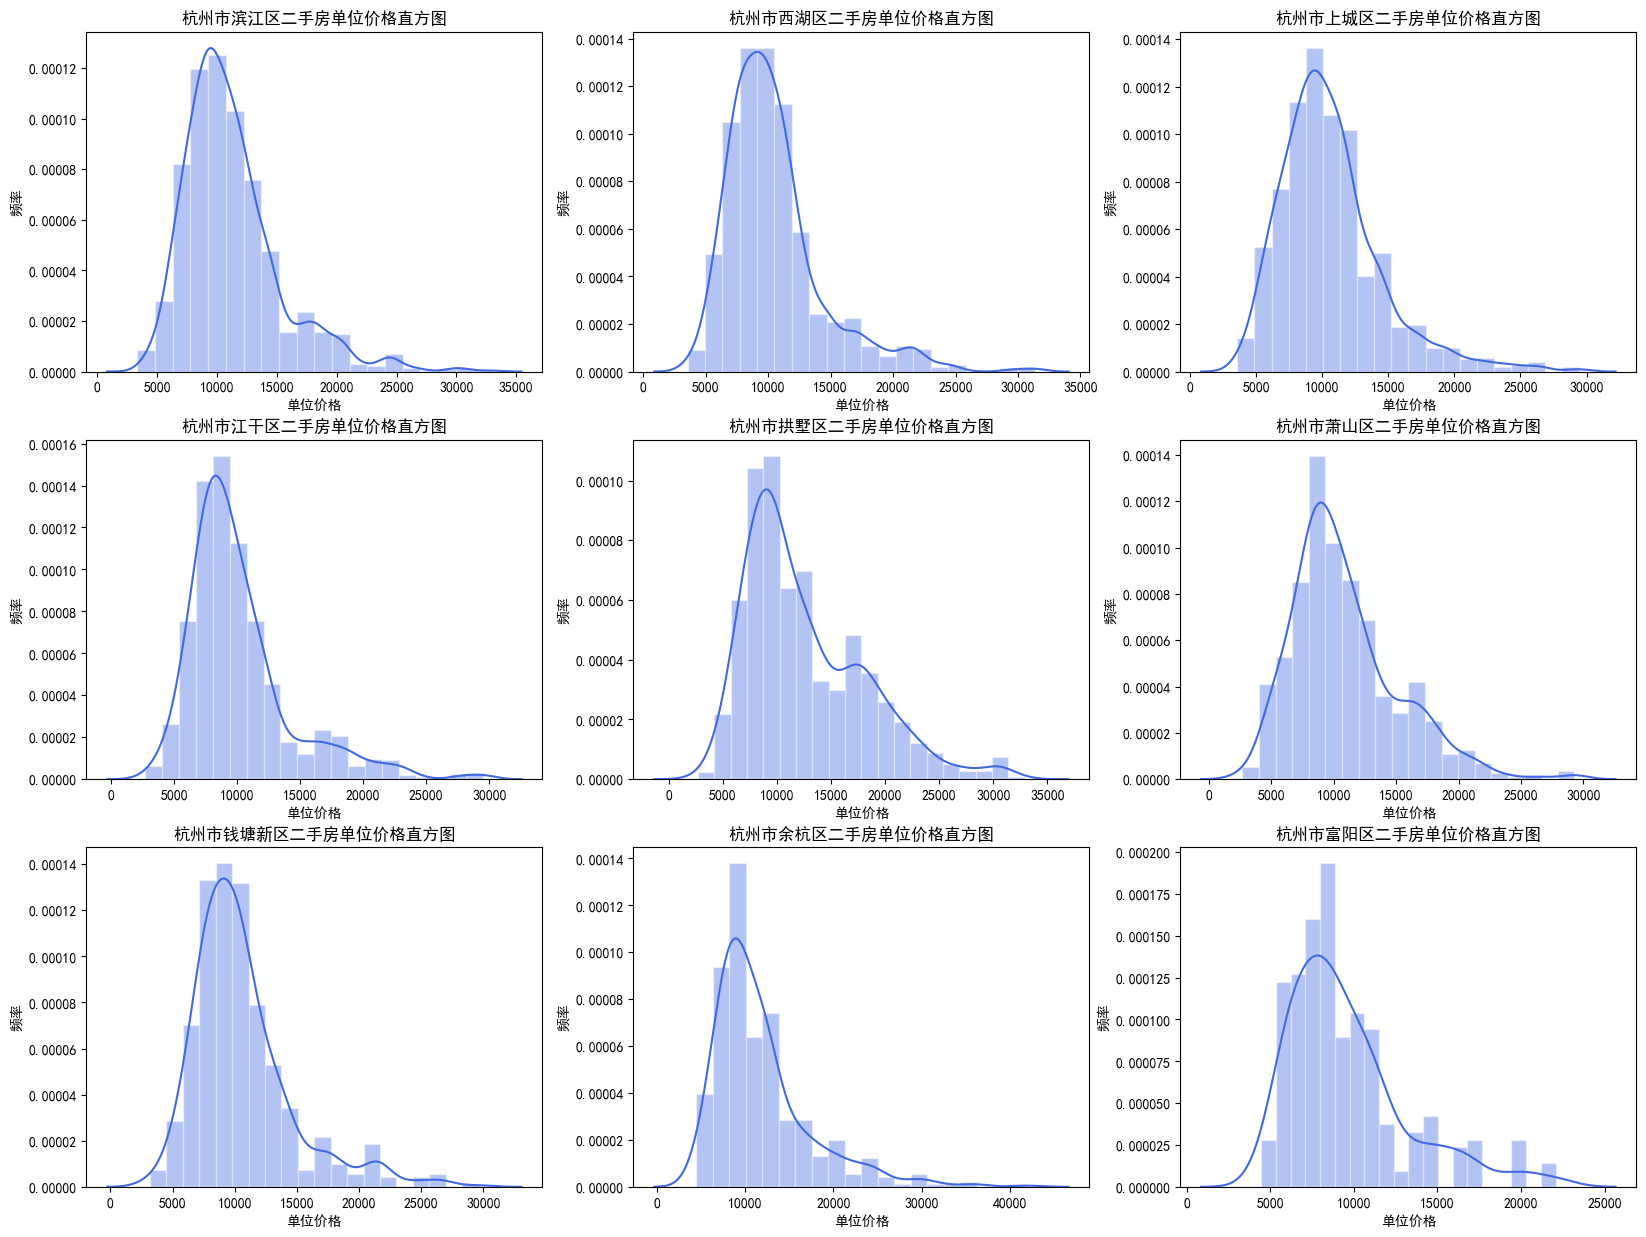

In [12]:
plt.figure(figsize=(20,15))
for i in range(len(areaName)):
    cur_data = data[ data['所属区县'] == areaName[i] ]
    plt.subplot(3,3,i+1)
    plt.title("杭州市" + areaName[i] + "二手房单位价格直方图")
    sns.distplot(cur_data['单位价格'], color="royalblue",bins=20, kde=True, hist_kws={"edgecolor":"w"})
    plt.xlabel("单位价格")
    plt.ylabel("频率")
plt.show()


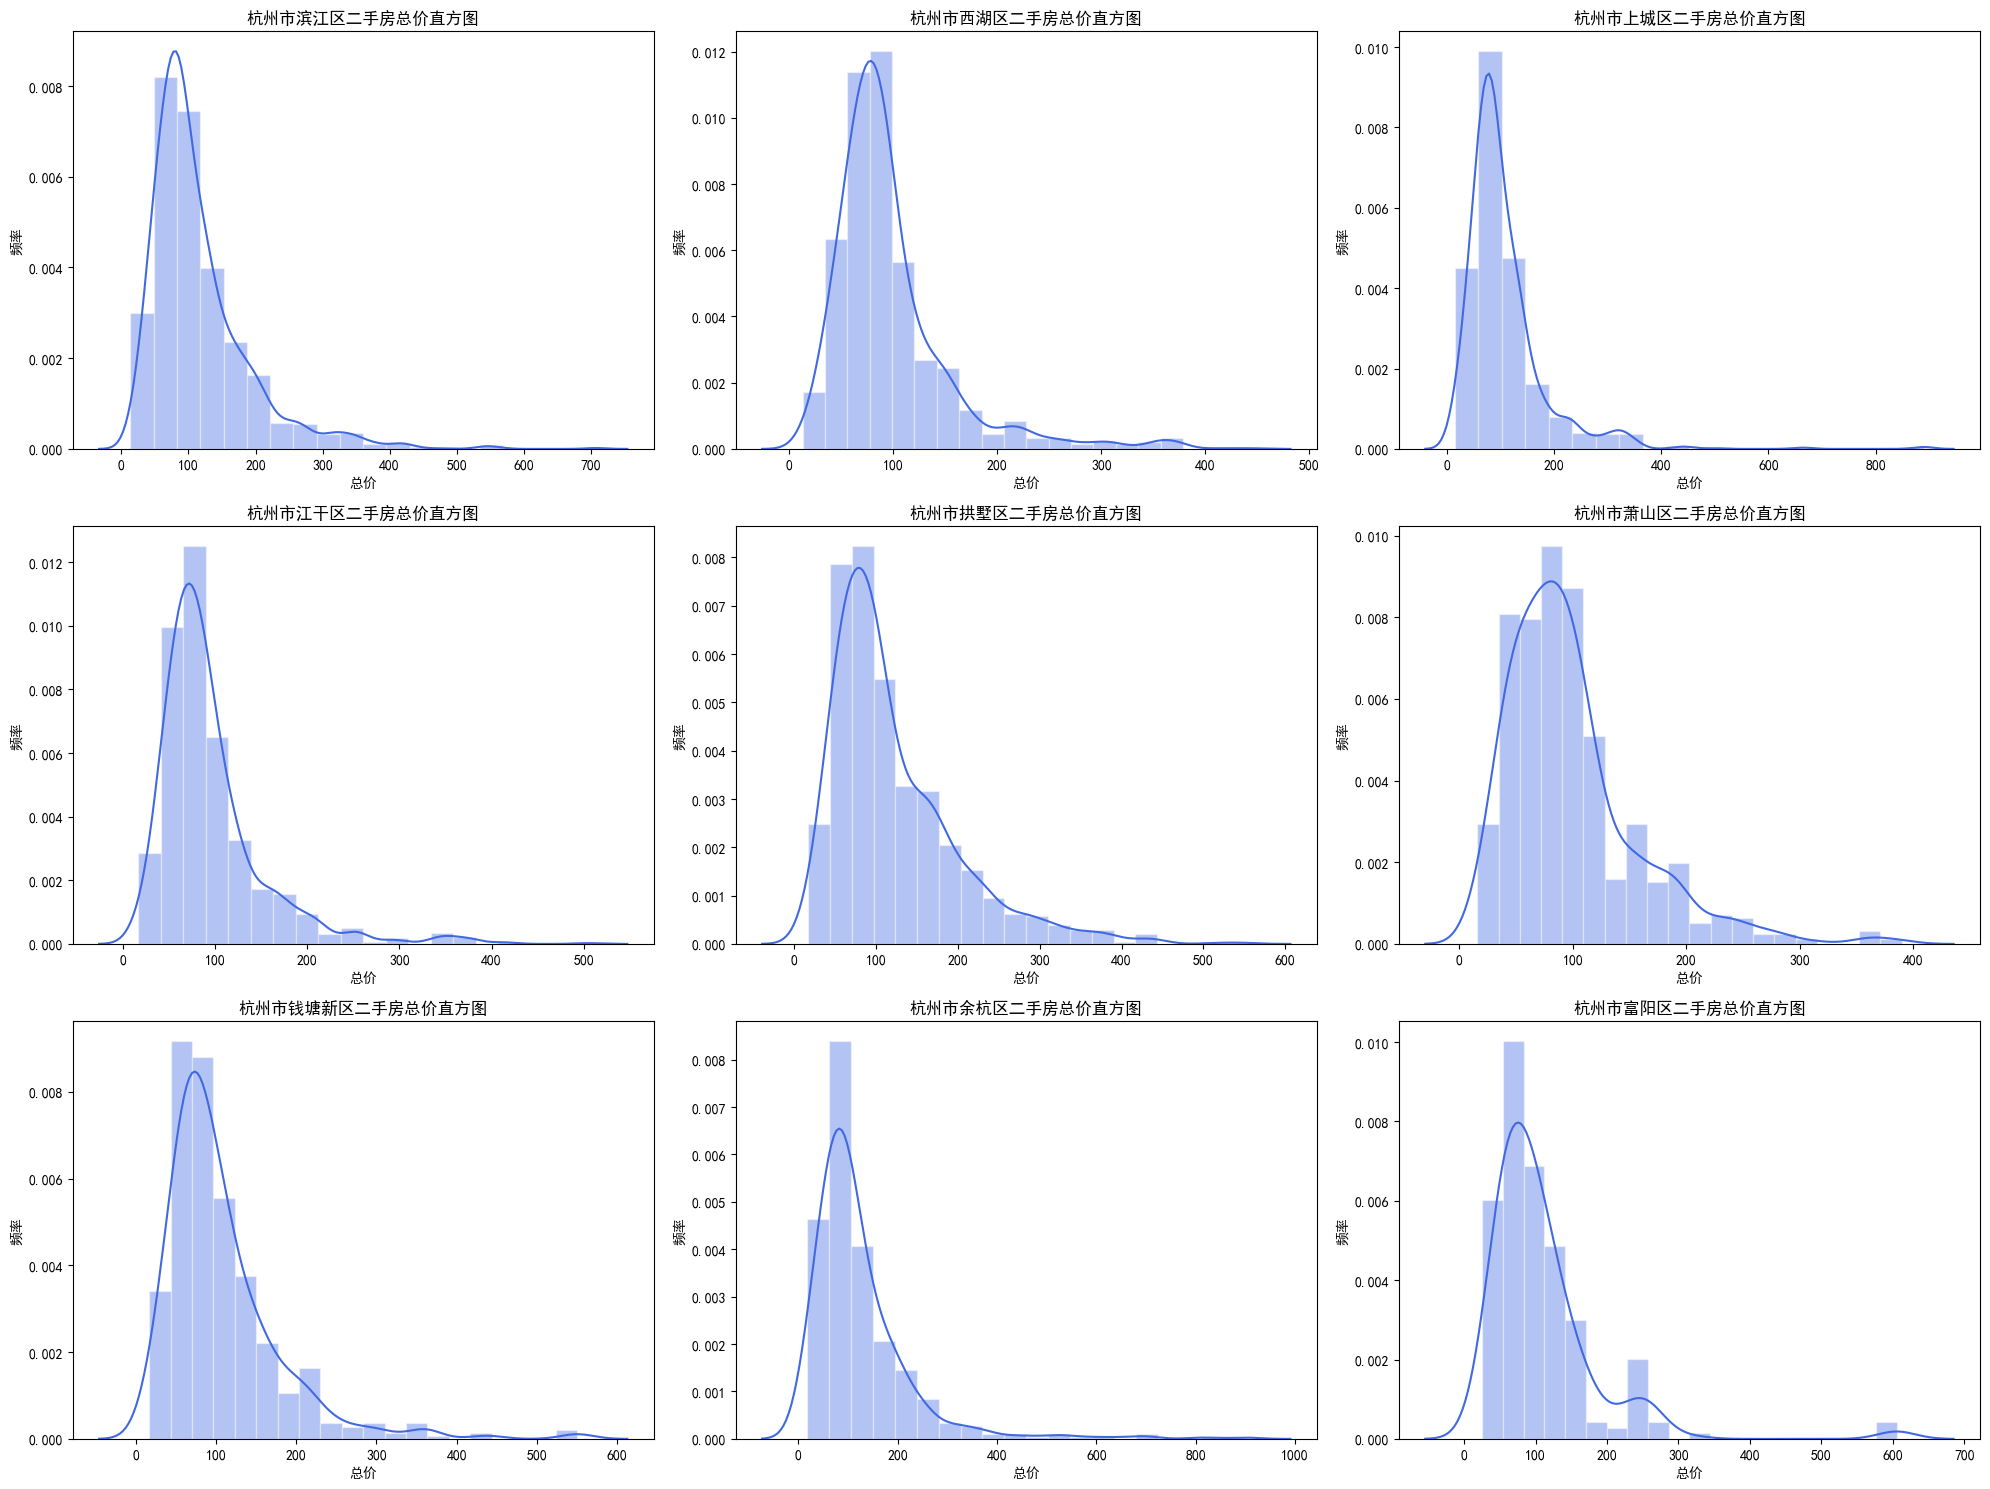

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(20,15))
for i in range(len(areaName)):
    cur_data = data[data['所属区县'] == areaName[i]]
    plt.subplot(3,3,i+1)
    plt.title("杭州市" + areaName[i] + "二手房总价直方图")
    sns.distplot(cur_data['总价'], color="royalblue", bins=20, kde=True, hist_kws={"edgecolor":"w"})
    plt.xlabel("总价")
    plt.ylabel("频率")
plt.tight_layout()  # Adjust subplots to fit into figure area.
plt.savefig('Hangzhou_Second_Hand_House_Prices.png')  # Save the figure as a PNG file
plt.show()

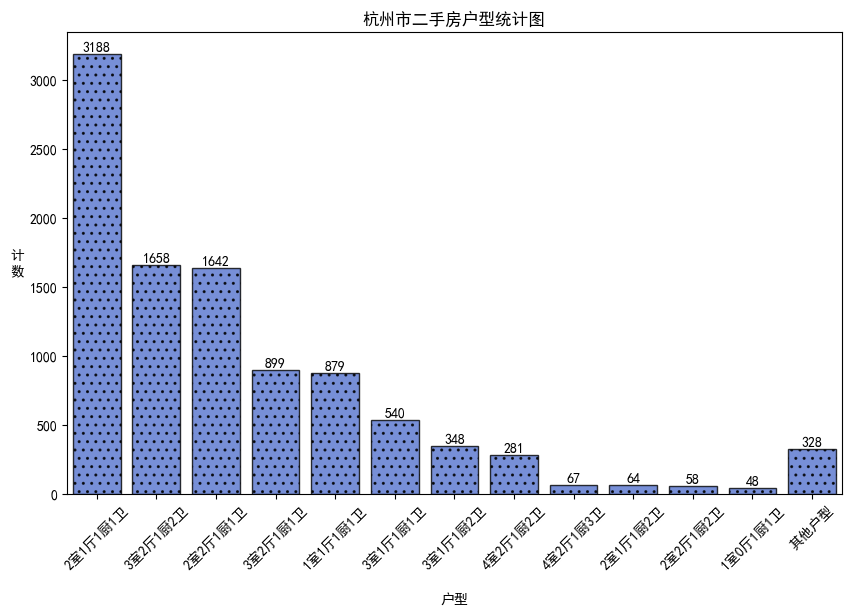

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

huxingName = list(data['房屋户型'].value_counts().index)
huxingCountList = list(data['房屋户型'].value_counts())

# Combine types with low counts into "其他户型"
otherCount = sum(huxingCountList[12:])
huxingName = huxingName[:12]
huxingCountList = huxingCountList[:12]
huxingName.append("其他户型")
huxingCountList.append(otherCount)

plt.figure(figsize=(10, 6))
plt.title("杭州市二手房户型统计图")
g = sns.barplot(x=huxingName, y=huxingCountList, alpha=0.8, color="royalblue", edgecolor="k", hatch="..")
plt.xlabel("\n户型")
plt.ylabel("计\n数", rotation='horizontal', verticalalignment='center', horizontalalignment='right')

for a, b in zip(range(len(huxingName)), huxingCountList):
    plt.text(a, b + 3, '%.f' % b, ha='center', va='bottom', fontsize=10)

plt.xticks(rotation=45)
plt.show()



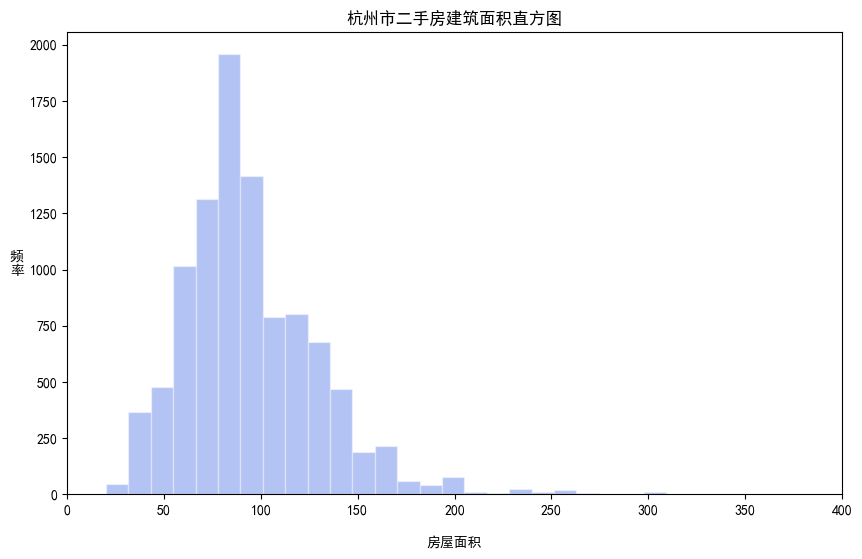

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

# Remove the unit '㎡' and convert to float
data['建筑面积'] = data['建筑面积'].str.replace('㎡', '').astype(float)

plt.figure(figsize=(10, 6))
plt.title("杭州市二手房建筑面积直方图")
sns.distplot(data['建筑面积'], color="royalblue", bins=25, kde=False, hist_kws={"edgecolor": "w"})
plt.xlabel("\n房屋面积")
plt.ylabel("频\n率", rotation='horizontal', verticalalignment='center', horizontalalignment='right')
plt.xlim(0, 400)
plt.show()



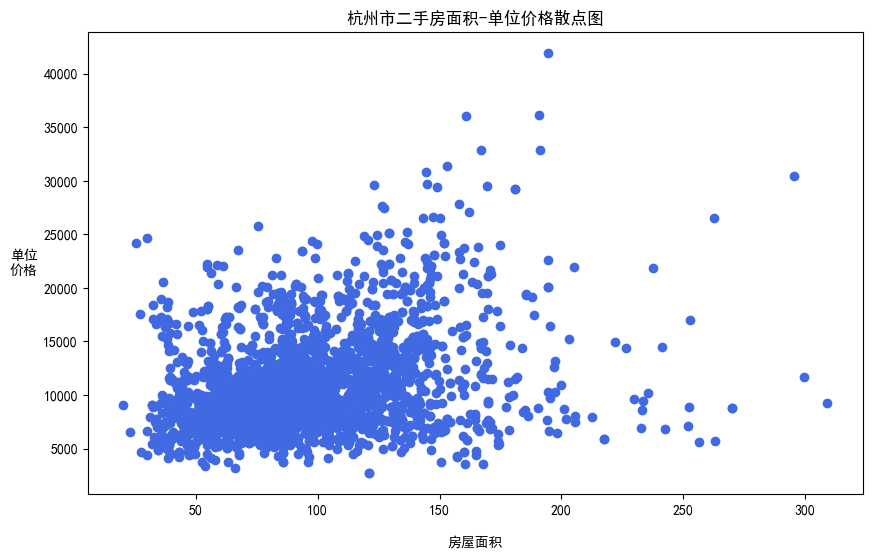

In [26]:
plt.figure(figsize=(10,6))
plt.title("杭州市二手房面积-单位价格散点图")
plt.scatter(data['建筑面积'], data['单位价格'],color="royalblue")
plt.xlabel("\n房屋面积")
plt.ylabel("单位\n价格", rotation = 'horizontal', verticalalignment = 'center', horizontalalignment = 'right')
plt.show()
# 二手房面积-单位价格散点图

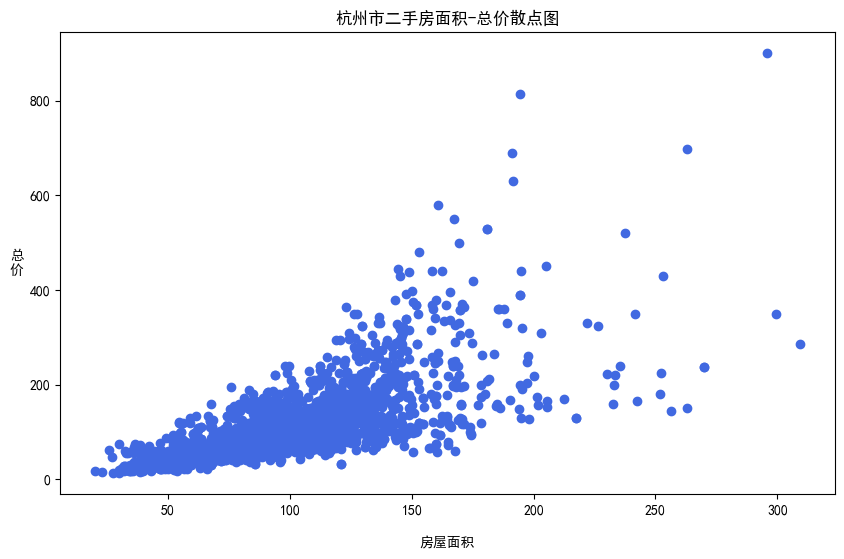

In [27]:
# 二手房面积-总价散点图
plt.figure(figsize=(10,6))
plt.title("杭州市二手房面积-总价散点图")
plt.scatter(data['建筑面积'], data['总价'],color="royalblue")
plt.xlabel("\n房屋面积")
plt.ylabel("总\n价", rotation = 'horizontal', verticalalignment = 'center', horizontalalignment = 'right')
plt.show()


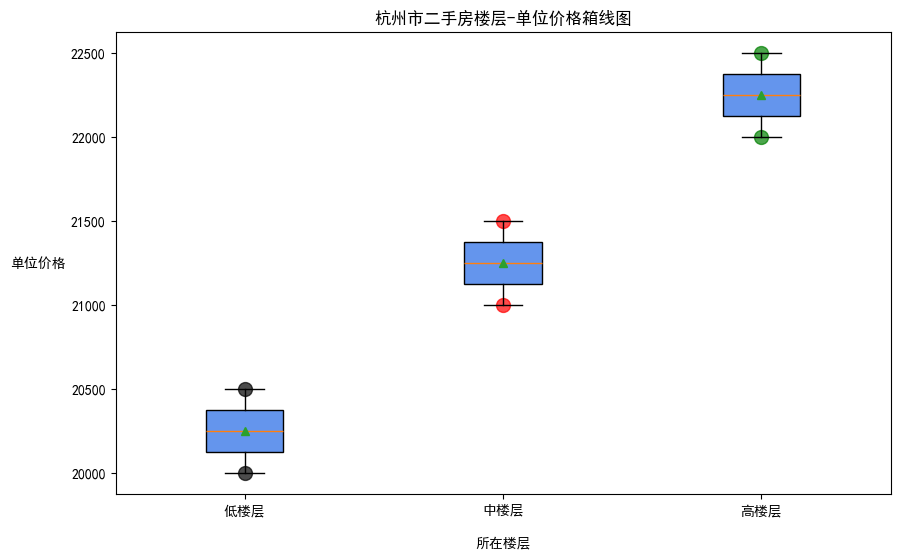

In [32]:
import matplotlib.pyplot as plt
import pandas as pd

# Example DataFrame setup (replace with your actual data loading method)
data = pd.DataFrame({
    '所在楼层': ['低楼层', '中楼层', '高楼层', '低楼层', '中楼层', '高楼层'],
    '单位价格': [20000, 21000, 22000, 20500, 21500, 22500]
})

louceng = [list(data[data['所在楼层'] == "低楼层"]["单位价格"]),
           list(data[data['所在楼层'] == "中楼层"]["单位价格"]),
           list(data[data['所在楼层'] == "高楼层"]["单位价格"])]

plt.figure(figsize=(10, 6))
plt.title("杭州市二手房楼层-单位价格箱线图")

# Create boxplot
boxprops = dict(facecolor="cornflowerblue", edgecolor="black")
plt.boxplot(louceng, labels=['低楼层', '中楼层', '高楼层'], patch_artist=True, boxprops=boxprops, showmeans=True)

# Overlay data points
colors = ['black', 'red', 'green']  # Color for each floor level
for i, prices in enumerate(louceng):
    y = prices
    x = [i + 1] * len(prices)
    plt.scatter(x, y, color=colors[i], alpha=0.7, s=100)  # Adjusted alpha and marker size (s)

plt.xlabel("\n所在楼层")
plt.ylabel("单位价格", rotation='horizontal', verticalalignment='center', horizontalalignment='right')
plt.show()


# 单位价格箱线图

低楼层: [300, 320]
中楼层: [350, 360]
高楼层: [400, 420]


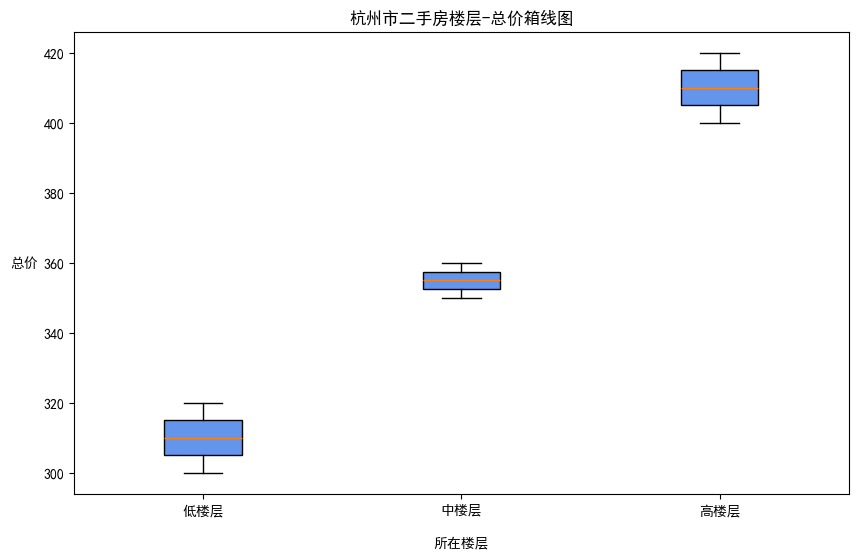

In [33]:
import matplotlib.pyplot as plt
import pandas as pd

# Example DataFrame setup (replace with your actual data loading method)
data = pd.DataFrame({
    '所在楼层': ['低楼层', '中楼层', '高楼层', '低楼层', '中楼层', '高楼层'],
    '总价': [300, 350, 400, 320, 360, 420]
})

louceng1 = [list(data[data['所在楼层'] == "低楼层"]["总价"]), 
            list(data[data['所在楼层'] == "中楼层"]["总价"]), 
            list(data[data['所在楼层'] == "高楼层"]["总价"])]

# Debug: Print the content of each list
print("低楼层:", louceng1[0])
print("中楼层:", louceng1[1])
print("高楼层:", louceng1[2])

plt.figure(figsize=(10, 6))
plt.title("杭州市二手房楼层-总价箱线图")
plt.boxplot(louceng1, labels=['低楼层', '中楼层', '高楼层'], patch_artist=True, boxprops={'facecolor':'cornflowerblue'})
plt.xlabel("\n所在楼层")
plt.ylabel("总价", rotation='horizontal', verticalalignment='center', horizontalalignment='right')
plt.show()



In [44]:
chaoxiang = []

for c in data['房屋朝向'].value_counts().index:
    chaoxiang.append(list(data[ data['房屋朝向'] == c ]["单位价格"]))

plt.figure(figsize=(15,10))
plt.title("杭州市二手房朝向-单位价格箱线图")
dd = plt.boxplot(chaoxiang, labels = data['房屋朝向'].value_counts().index, patch_artist=True,boxprops={'facecolor':'cornflowerblue'})
plt.xlabel("朝向")
plt.ylabel("单位价格", rotation = 'horizontal', verticalalignment = 'center', horizontalalignment = 'right')
plt.xticks(rotation=90)
plt.show()


KeyError: '房屋朝向'

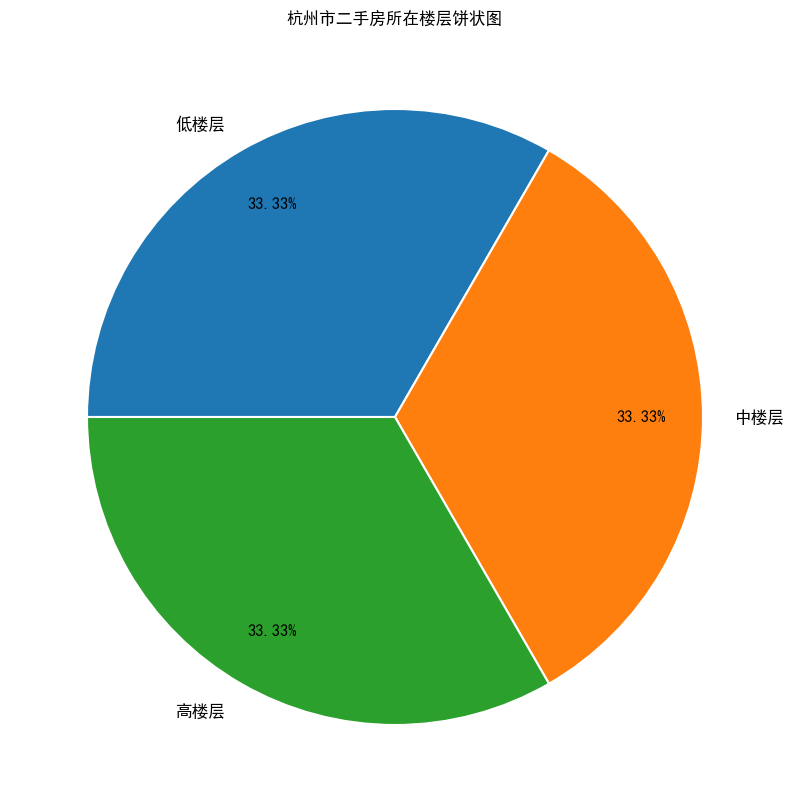

In [42]:
plt.figure(figsize=(12,10))
plt.title("杭州市二手房所在楼层饼状图")
louceng2 = data['所在楼层'].value_counts()
plt.pie(louceng2, labels = louceng2.index, autopct='%.2f%%', # 设置百分比的格式，这里保留一位小数
        pctdistance=0.8,  # 设置百分比标签与圆心的距离
        labeldistance = 1.1, # 设置教育水平标签与圆心的距离
        startangle = 180, # 设置饼图的初始角度
        counterclock = False, # 是否逆时针，这里设置为顺时针方向
        wedgeprops = {'linewidth': 1.5, 'edgecolor':'w'},# 设置饼图内外边界的属性值
        textprops = {'fontsize':12, 'color':'black'}, # 设置文本标签的属性值
       )
plt.show()


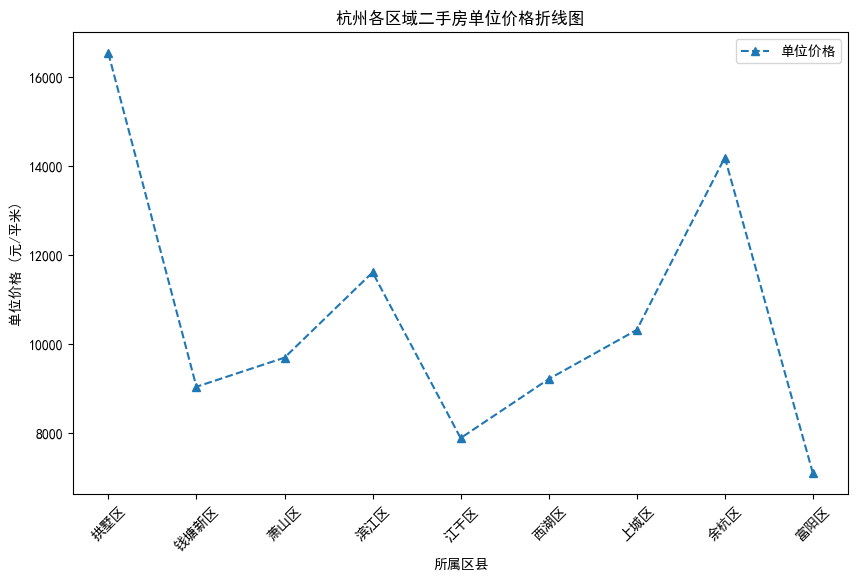

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# 警告管理和matplotlib设置
warnings.filterwarnings("ignore")
plt.rcParams['font.sans-serif'] = ['SimHei']  # 显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 显示负号

# 数据加载
data_path = r"C:\Users\wang\Desktop\毕设论文\房价预测代码\data\链家杭州二手房数据.xlsx"  # 请替换为正确的路径
data = pd.read_excel(data_path, na_values=np.nan)
data = data[data.columns[:-4]]  # 去掉最后四列

# 数据清洗
data['单位价格'] = data['单位价格'].replace('元/平米', '', regex=True).astype(float)

# 数据处理和可视化
areaName = data['所属区县'].unique()
meanValue = []
for i in range(len(areaName)):
    cur_data = data[data['所属区县'] == areaName[i]]
    meanValue.append(round(cur_data['单位价格'].mean(), 2))

plt.figure(figsize=(10, 6))
plt.title("杭州各区域二手房单位价格折线图")
plt.plot(range(len(areaName)), meanValue, '--^', label="单位价格")
plt.xticks(range(len(areaName)), labels=areaName, rotation=45)
plt.legend()
plt.xlabel("所属区县")
plt.ylabel("单位价格 (元/平米)")
plt.show()


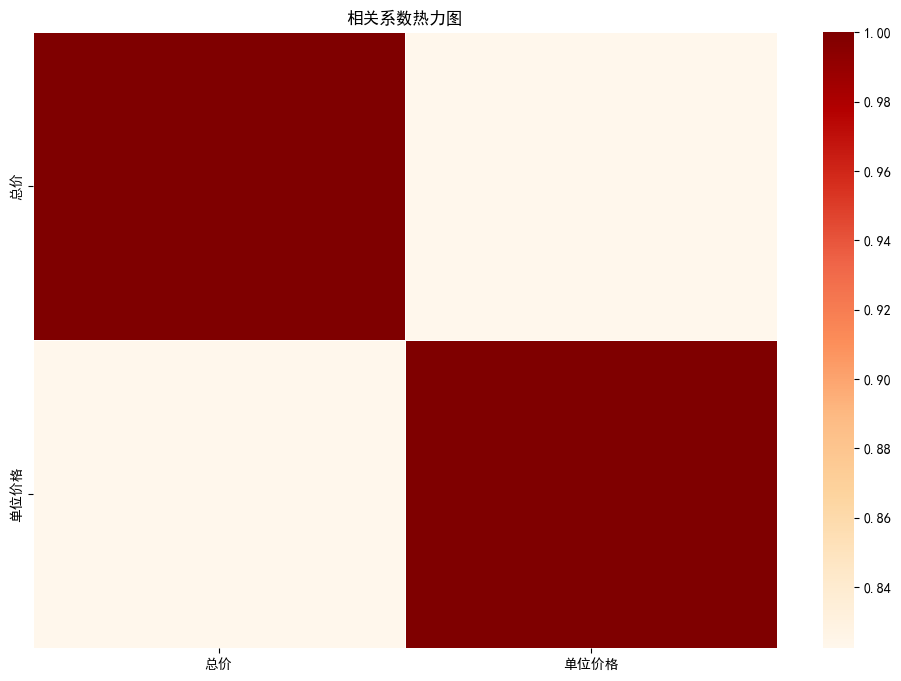

In [5]:
corrColName = list(data.dtypes[ data.dtypes != 'object' ].index)
corrDf = data[corrColName]
data_corr = corrDf.corr()
price_corr = dict(data_corr.iloc[0])
price_corr = sorted(price_corr.items(), key=lambda x: abs(x[1]), reverse=True)
price_corr_cols = [ r[0] for r in price_corr ]
price_data = data_corr[price_corr_cols].loc[price_corr_cols]
plt.figure(figsize=(12, 8))
plt.title("相关系数热力图")
ax = sns.heatmap(price_data, linewidths=0.5, cmap='OrRd', cbar=True)
plt.show()


In [46]:
print(price_corr)

[('总价', 1.0)]


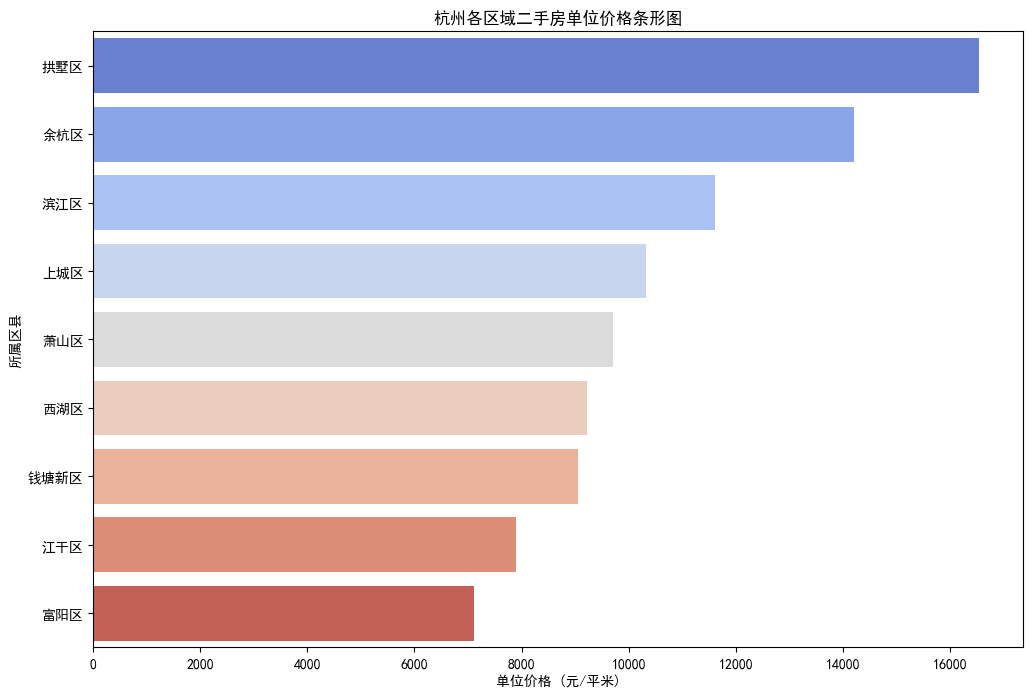

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# 警告管理和matplotlib设置
warnings.filterwarnings("ignore")
plt.rcParams['font.sans-serif'] = ['SimHei']  # 显示中文标签
plt.rcParams['axes.unicode_minus'] = False  # 显示负号

# 数据加载
data_path = r"C:\Users\wang\Desktop\毕设论文\房价预测代码\data\链家杭州二手房数据.xlsx"  # 请替换为正确的路径
data = pd.read_excel(data_path, na_values=np.nan)
data = data[data.columns[:-4]]  # 去掉最后四列

# 数据清洗
data['单位价格'] = data['单位价格'].replace('元/平米', '', regex=True).astype(float)

# 数据处理和可视化
areaName = data['所属区县'].unique()
meanValue = []
for i in range(len(areaName)):
    cur_data = data[data['所属区县'] == areaName[i]]
    meanValue.append(round(cur_data['单位价格'].mean(), 2))

# 为了绘制条形图，创建包含区县名和均值的DataFrame，并按均值排序
price_df = pd.DataFrame({'区县': areaName, '平均单位价格': meanValue})
price_df = price_df.sort_values(by='平均单位价格', ascending=False)

plt.figure(figsize=(12, 8))
plt.title("杭州各区域二手房单位价格条形图")
sns.barplot(x='平均单位价格', y='区县', data=price_df, palette='coolwarm')
plt.xlabel("单位价格 (元/平米)")
plt.ylabel("所属区县")
plt.show()
